In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# 03 — Brand contracts: does a brand request leak into the specs? (Phase B)

Phase B of `grum_formalization.md` §8. Brand contracts exist for **qwen-32B** (`brand=Apple`, `brand=Dell`) and
**qwen-72B** (`brand=Dell`), from the contract-path runs of October. Two of them have a useful twist:
- `brand=Apple` **agrees** with qwen-32B's taste (Apple is its top brand);
- `brand=Dell` **fights** it (Dell is 4th of 5 in qwen-32B; 2nd in qwen-72B).

Same model as notebook 02: push ρ and self-flattening σ on brand, leakage κ into screen and RAM.
Only 3 runs and one family, so this notebook is a **first look**, not a result to generalise.

In [2]:
from grumish import *
import matplotlib.pyplot as plt
setup_plots()
FIG = "figs/GRUMish"
R = load_all(["qwen-32B", "qwen-72B"])
BR = [("qwen-32B", "brand=Apple"), ("qwen-32B", "brand=Dell"), ("qwen-72B", "brand=Dell")]

## 1. The weights under a brand request

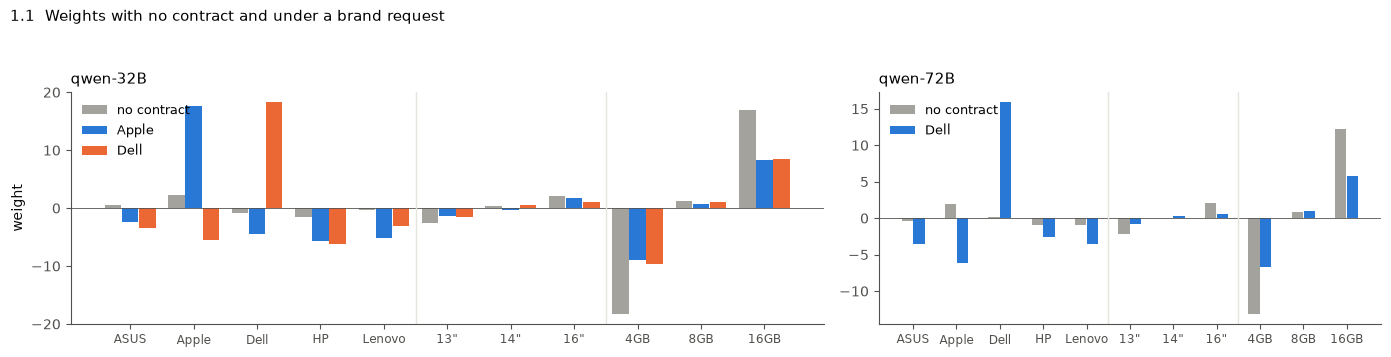

qwen-32B brand=Apple: lead of Apple before +1.6, after +20.0
qwen-32B brand=Dell: lead of Dell before -3.1, after +21.4
qwen-72B brand=Dell: lead of Dell before -1.8, after +18.5


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [3, 2]})
x = np.arange(len(LV))
for ax, m, cons in [(axes[0], "qwen-32B", ["none", "brand=Apple", "brand=Dell"]), (axes[1], "qwen-72B", ["none", "brand=Dell"])]:
    cols = [GRAY, BLUE, ORANGE][:len(cons)]
    for k, (c, col) in enumerate(zip(cons, cols)):
        ax.bar(x + (k - (len(cons) - 1) / 2) * 0.27, R[(m, c)].w.values, 0.26, color=col, label=short(c) if c != "none" else "no contract")
    ax.axhline(0, color=INK2, lw=0.6)
    for b in (4.5, 7.5): ax.axvline(b, color=GRID, lw=1)
    ax.set_xticks(x, [l.replace("-inch", '"') for _, l in LV], fontsize=8.5); ax.legend(frameon=False, fontsize=9, loc="upper left")
    ax.set_title(m, loc="left")
axes[0].set_ylabel("weight")
fig.suptitle("1.1  Weights with no contract and under a brand request", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(f"{FIG}/03_1_brand_weights.png", dpi=150); plt.show()
for m, c in BR:
    a, w = R[(m, "none")].w["brand"], R[(m, c)].w["brand"]; l = parse(c)["brand"]
    print(f"{m} {c}: lead of {l} before {a[l] - a.drop(l).max():+.1f}, after {w[l] - w.drop(l).max():+.1f}")

- **A brand request works like a target**, like a screen request: the requested brand ends up leading by +18 … +21,
  whatever the start. Apple (already liked by qwen-32B): +1.6 → +20.0. Dell (disliked): −3.1 → +21.4 (qwen-32B),
  −1.8 → +18.5 (qwen-72B).
- **The RAM bars about halve** under a brand request, and the screen bars shrink too (next section).

## 2. Leakage between brand and the specs, both directions

κ = how much of the other feature's taste is flattened (0 = untouched, 1 = gone). Left: a **brand** request, its
effect on screen and RAM. Right, for the same two models: a **screen or RAM** request, its effect on brand (all 3
levels from notebook 02).

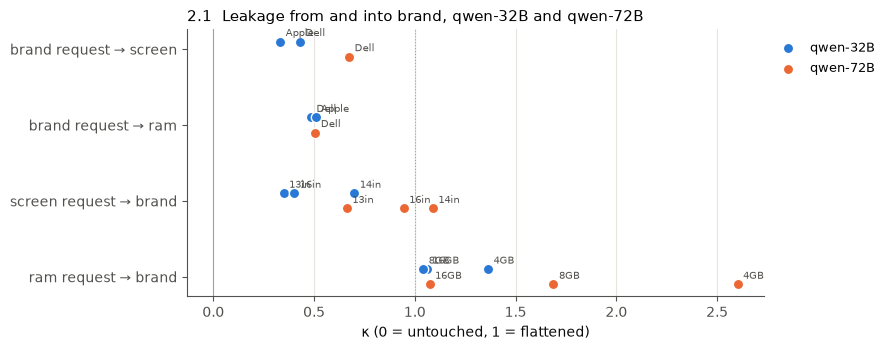

                   min               max         
model         qwen-32B qwen-72B qwen-32B qwen-72B
f      g                                         
brand  ram        0.48     0.51     0.51     0.51
       screen     0.33     0.67     0.43     0.67
ram    brand      1.04     1.07     1.36     2.60
       screen     0.10    -0.06     1.82     1.46
screen brand      0.35     0.66     0.70     1.09
       ram        0.45     0.37     0.57     0.42


In [4]:
rows = []
for (m, c) in R:
    p = parse(c)
    if len(p) != 1: continue
    (f, l), = p.items(); P = fit_struct(R[(m, "none")].w, [(f, l, R[(m, c)].w)], True)
    for g in FEATS:
        if g != f: rows.append(dict(model=m, c=c, f=f, g=g, kappa=P["kappa"][(f, g)]))
KB = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.6))
PAIRS = [("brand", "screen"), ("brand", "ram"), ("screen", "brand"), ("ram", "brand")]
for i, (f, g) in enumerate(PAIRS):
    for m, col in [("qwen-32B", BLUE), ("qwen-72B", ORANGE)]:
        s = KB[(KB.model == m) & (KB.f == f) & (KB.g == g)]
        ax.scatter(s.kappa, np.full(len(s), i) + (0.1 if m == "qwen-72B" else -0.1), s=55, color=col, edgecolor="white", zorder=3,
                   label=m if i == 0 else None)
        for _, r in s.iterrows():
            ax.annotate(short(r.c), (r.kappa, i + (0.1 if m == "qwen-72B" else -0.1)), xytext=(4, 4), textcoords="offset points", fontsize=7, color=INK2)
ax.axvline(0, color=GRAY, lw=0.8); ax.axvline(1, color=GRAY, lw=0.8, ls=":")
ax.set_yticks(range(4), [f"{f} request → {g}" for f, g in PAIRS]); ax.invert_yaxis(); ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_xlabel("κ (0 = untouched, 1 = flattened)"); ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("2.1  Leakage from and into brand, qwen-32B and qwen-72B", loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/03_2_leak_asymmetry.png", dpi=150); plt.show()
print(KB.pivot_table(index=["f", "g"], columns="model", values="kappa", aggfunc=["min", "max"]).round(2).to_string())

- **With all-pairs weights the leakage runs both ways.** A brand request halves the RAM weight (κ 0.48–0.51) and shrinks
  screen (0.33–0.67). A RAM request turns brand (1.04–2.60), a screen request flattens it (0.35–1.09).
- **Why it looked one-way before (CP weights, before 11-03: brand → RAM only 0.16–0.20):** the two measures answer
  different questions. Inside each brand, 4GB vs 16GB is still decided by RAM almost as strongly as before (CP RAM range
  38 → 31 in qwen-32B). What halves is how much RAM **decides across all pairs**: once brand leads by +20, "Dell 4GB vs
  ASUS 16GB" is decided by brand, not RAM (RAM range in utility 35 → 18, in every brand alike).
- So a brand request does not change how much the model cares about RAM **in a tie**; it changes the **priority order**:
  the requested feature moves to the top and the others decide fewer pairs. For predicting choices, that is the part
  that matters.

## 3. Inside the contract: does the model keep its own order? (the books question)

In [books_vs_laptops.ipynb](../books_vs_laptops.ipynb) the key difference between the domains was this: among the items
that **meet** the contract, is the model's old order kept (Spearman ρ inside, 1 = kept)? Here it is for every
one-requirement laptop contract, brand ones included.

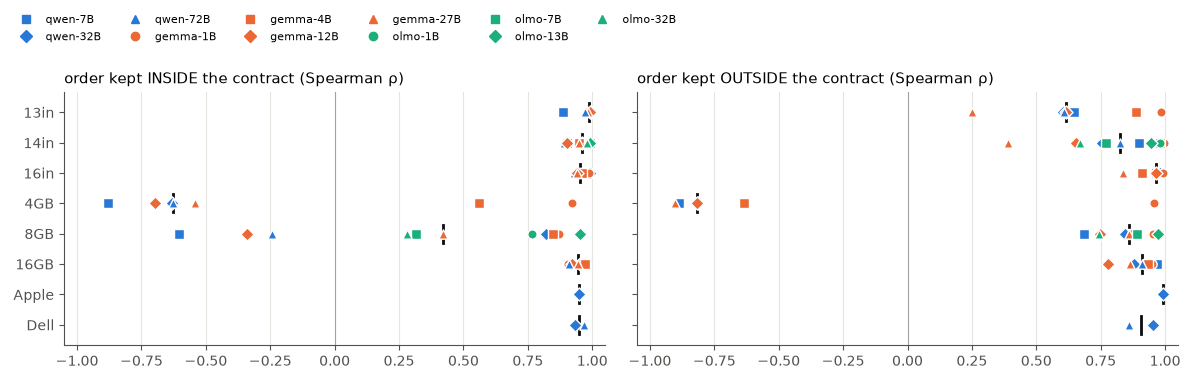

               inside             outside            
               median   min   max  median   min   max
c                                                    
screen=13-inch   0.99  0.89  1.00    0.62  0.25  0.98
screen=14-inch   0.96  0.89  1.00    0.82  0.39  0.99
screen=16-inch   0.95  0.93  0.99    0.97  0.84  0.99
ram=4GB         -0.63 -0.88  0.92   -0.82 -0.91  0.96
ram=8GB          0.42 -0.60  0.95    0.86  0.69  0.98
ram=16GB         0.94  0.91  0.97    0.91  0.78  0.97
brand=Apple      0.95  0.95  0.95    0.99  0.99  0.99
brand=Dell       0.95  0.93  0.97    0.91  0.86  0.95


In [5]:
RA = load_all()
from scipy.stats import spearmanr
rows = []
for (m, c), r in RA.items():
    p = parse(c)
    if len(p) != 1 or m == "qwen-0.5B": continue
    mk = meets(c)
    rows.append(dict(model=m, c=c, f=list(p)[0], inside=spearmanr(RA[(m, "none")].u[mk], r.u[mk])[0],
                     outside=spearmanr(RA[(m, "none")].u[~mk], r.u[~mk])[0]))
IN = pd.DataFrame(rows)
order = ["screen=13-inch", "screen=14-inch", "screen=16-inch", "ram=4GB", "ram=8GB", "ram=16GB", "brand=Apple", "brand=Dell"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col in zip(axes, ["inside", "outside"]):
    for i, c in enumerate(order):
        s = IN[IN.c == c]
        for _, r in s.iterrows():
            st = model_style(r.model)
            ax.scatter(r[col], i, s=45, color=st["color"], marker=st["marker"], edgecolor="white", zorder=3)
        ax.plot([s[col].median()] * 2, [i - 0.3, i + 0.3], color=INK, lw=2)
    ax.axvline(0, color=GRAY, lw=0.8); ax.set_xlim(-1.05, 1.05); ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_title(f"order kept {col.upper()} the contract (Spearman ρ)", loc="left")
axes[0].set_yticks(range(len(order)), [short(c) for c in order]); axes[0].invert_yaxis()
handles = [plt.Line2D([], [], ls="", marker=model_style(m)["marker"], color=model_style(m)["color"], label=m) for m in REAL]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.005, 1.0), ncol=6, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/03_3_inside_outside.png", dpi=150); plt.show()
print(IN.groupby("c")[["inside", "outside"]].agg(["median", "min", "max"]).reindex(order).round(2).to_string())

- **Screen, brand and `16GB` requests are filters**: among the laptops that meet them, the old order is kept (median ρ
  0.94–0.99, all models). This is the laptop picture from books_vs_laptops.
- **The RAM requests that fight the taste are not.** `8GB`: median ρ inside 0.42 (−0.60 … 0.95); `4GB`: **−0.63**. Inside
  the 4GB laptops the order turns, because the screen taste turns and Apple falls (notebook 02).
- **Outside, `4GB` reverses the order too** (median −0.82): the 8GB laptops now beat the 16GB ones — the ideal point of
  notebook 02 §3b. `13-inch` does the same, more mildly (0.62).
- So "the contract is a filter" holds only when the request does not fight a strong taste. A request against RAM
  rewrites the model's taste around the request — closer to what the books showed.

## 4. Predict one brand request from the other

The same test as notebook 02 §5, with the only two brand levels we have (qwen-32B): fit σ, ρ, κ on `brand=Dell`,
predict `brand=Apple`, and the other way around.

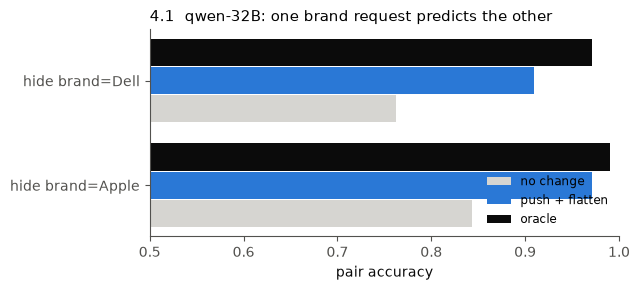

pred    no change  push + flatten  oracle
hidden                                   
Apple       0.843           0.971   0.990
Dell        0.763           0.909   0.971


In [6]:
m = "qwen-32B"; a = R[(m, "none")].w
rows = []
for test_l, train_l in [("Apple", "Dell"), ("Dell", "Apple")]:
    test = R[(m, f"brand={test_l}")]
    P = fit_struct(a, [("brand", train_l, R[(m, f"brand={train_l}")].w)], True)
    for name, wp in {"no change": a, "push + flatten": predict_struct(a, P, {"brand": test_l}), "oracle": test.w}.items():
        rows.append(dict(hidden=test_l, pred=name, acc=pair_accuracy(additive_utility(wp), test.D)))
BT = pd.DataFrame(rows).pivot(index="hidden", columns="pred", values="acc")[["no change", "push + flatten", "oracle"]]
fig, ax = plt.subplots(figsize=(6.5, 3))
for k, (p, col) in enumerate(zip(BT.columns, [LGRAY, BLUE, INK])):
    ax.barh(np.arange(2) + (k - 1) * 0.27, BT[p], 0.26, color=col, label=p)
ax.set_yticks(range(2), [f"hide brand={h}" for h in BT.index]); ax.set_xlim(0.5, 1); ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.set_xlabel("pair accuracy"); ax.set_title("4.1  qwen-32B: one brand request predicts the other", loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/03_4_brand_transfer.png", dpi=150); plt.show()
print(BT.round(3).to_string())

- **One brand run predicts the other** (qwen-32B): hide `Apple` 0.843 → **0.971** (oracle 0.990); hide `Dell` 0.763 →
  **0.909** (oracle 0.971). This holds although one request agrees with the taste and the other fights it.
- Caveat: one model, two levels. Brand contracts for gemma-27B and olmo-32B (queued 11-02) would turn this into a result.